# Do the style features separate abstracts before and after ChatGPT?

We have no ground truth (no paper is known to be AI-written), so this notebook uses **publication year** as a proxy:
2020–2022 abstracts (BEFORE) were written before ChatGPT (Nov 2022), and 2024–2025 abstracts (AFTER) may include LLM-assisted text.
2023 is a transition year (papers submitted a few months after ChatGPT's release), as in the vocabulary analysis of the paper:
it stays in the PCA and the descriptive plots, but is left out of every BEFORE vs AFTER comparison.

A shift between the periods is consistent with LLM use, but it is **not proof**: topics, templates and authors change too
(for example, many recent ISMIR papers study LLMs). Read every result below as "the features changed", not "the papers are AI-written".

Input: `data/processed/features_v1.csv`, from `python -m analysis.features` (one row per abstract).
`n_words` is a control column (`CONTROL_COLUMNS` in `analysis/features.py`), not a style feature: it is left out of every analysis below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import false_discovery_control, mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES_CSV = "../data/processed/features_v1.csv"
CHATGPT = 2022.5  # between the last pre-ChatGPT year and the transition year
BEFORE_YEARS = [2020, 2021, 2022]
AFTER_YEARS = [2024, 2025]  # 2023 is a transition year, left out of every comparison

# Colors from the dataviz reference palette (light surface).
SURFACE, TEXT, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, RED, CONTEXT = "#2a78d6", "#eb6834", "#e34948", "#d3d2cc"  # series 1, series 2, diverging +, context
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", RED])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

In [2]:
df = pd.read_csv(FEATURES_CSV)
df["period"] = np.select([df.year.isin(BEFORE_YEARS), df.year.isin(AFTER_YEARS)], ["before", "after"], "transition")
# Length is not a style feature (the generation prompt fixes it): see CONTROL_COLUMNS in analysis/features.py.
CONTROL = ["n_words"]
used = [c for c in df.columns if c not in ("paper_id", "year", "source", "period", *CONTROL)]
assert not df[used].isna().any().any(), "NaN features: the scaler and the PCA need complete rows"
print(f"{len(df)} abstracts, {len(used)} features used")
df.groupby("year").agg(abstracts=("paper_id", "size"), median_words=("n_words", "median")).T

655 abstracts, 25 features used


year,2020,2021,2022,2023,2024,2025
abstracts,115.0,104.0,113.0,101.0,123.0,99.0
median_words,178.0,178.5,179.0,167.0,177.0,181.0


## 1. PCA

All features are standardized (mean 0, SD 1), so each counts the same. The scaler and the PCA use all 655 abstracts, 2023 included.

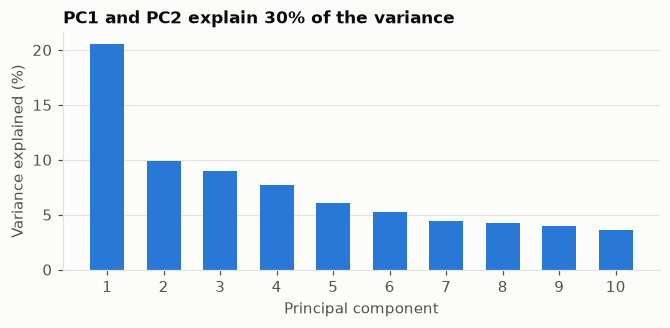

In [3]:
X = StandardScaler().fit_transform(df[used])
pca = PCA().fit(X)
pcs = pca.transform(X)
df["PC1"], df["PC2"] = pcs[:, 0], pcs[:, 1]
explained = 100 * pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 2.8))
k = 10
ax.bar(range(1, k + 1), explained[:k], color=BLUE, width=0.6)
ax.set(xlabel="Principal component", ylabel="Variance explained (%)", xticks=range(1, k + 1))
ax.grid(axis="x", visible=False)
ax.set_title(f"PC1 and PC2 explain {explained[:2].sum():.0f}% of the variance")
plt.show()

## 2. PC1 vs PC2, one panel per year

Gray: all 655 abstracts. Blue: the abstracts of that year. The cross is that year's mean.
If LLM use changed the style, the later panels should drift away from the earlier ones.

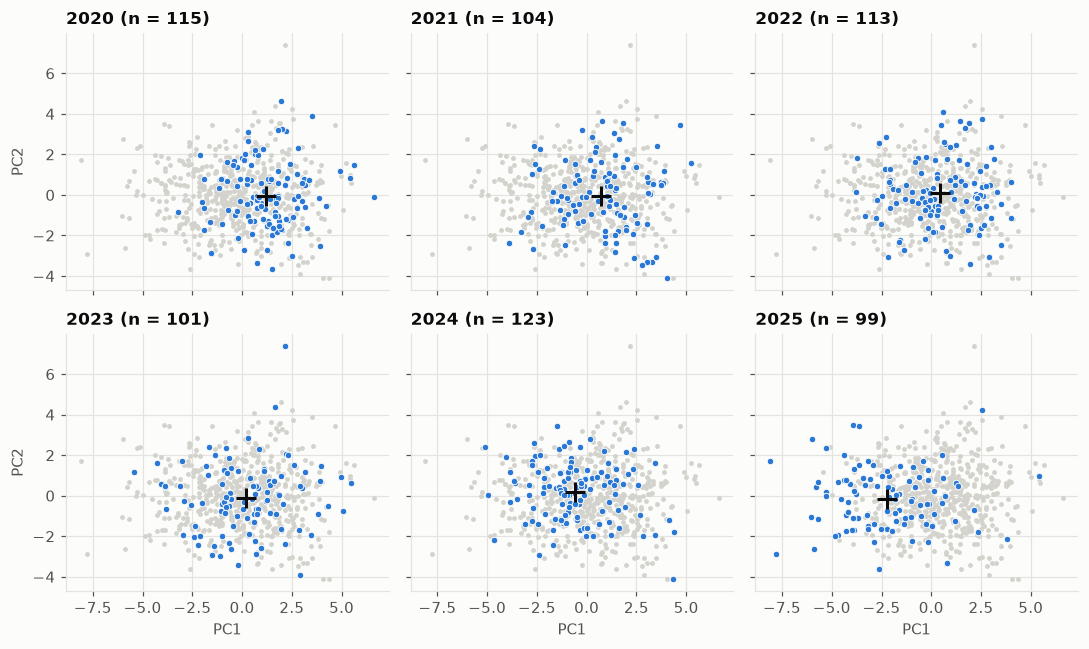

In [4]:
years = sorted(df.year.unique())
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex=True, sharey=True)
for ax, year in zip(axes.flat, years):
    sub = df[df.year == year]
    ax.scatter(df.PC1, df.PC2, s=10, color=CONTEXT, linewidths=0)
    ax.scatter(sub.PC1, sub.PC2, s=18, color=BLUE, edgecolors=SURFACE, linewidths=0.6)
    ax.scatter(sub.PC1.mean(), sub.PC2.mean(), marker="+", s=160, color=TEXT, linewidths=2)
    ax.set_title(f"{year} (n = {len(sub)})")
for ax in axes[1]:
    ax.set_xlabel("PC1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC2")
fig.tight_layout()
plt.show()

## 3. Timeline: mean position per year

Mean PC score per year with a 95% confidence interval. The dotted line is the 2020–2022 mean. The dashed line on PC1 is the 2020–2022 linear trend extended to 2025 (section 3b).

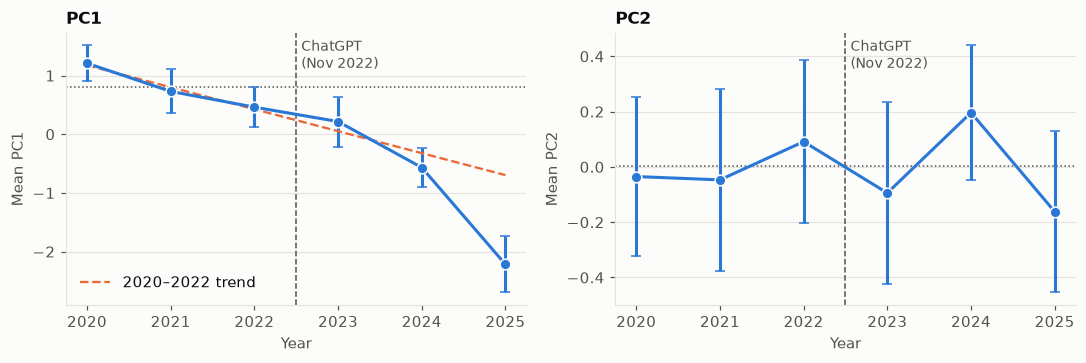

year,2020,2021,2022,2023,2024,2025
PC1,1.21,0.73,0.46,0.22,-0.57,-2.22
PC2,-0.03,-0.05,0.09,-0.09,0.20,-0.16


In [5]:
def trend_line(stats):
    """Linear fit of the yearly means over BEFORE_YEARS."""
    return np.polyfit(BEFORE_YEARS, stats.loc[BEFORE_YEARS, "mean"], 1)


def timeline(ax, column, trend=False):
    stats = df.groupby("year")[column].agg(["mean", "sem"])
    ax.axvline(CHATGPT, color=MUTED, linestyle="--", linewidth=1)
    ax.axhline(df.loc[df.period == "before", column].mean(), color=MUTED, linestyle=":", linewidth=1)
    ax.errorbar(stats.index, stats["mean"], yerr=1.96 * stats["sem"], color=BLUE, linewidth=2,
                marker="o", markersize=7, markeredgecolor=SURFACE, capsize=3)
    if trend:
        ax.plot(stats.index, np.polyval(trend_line(stats), stats.index), color=ORANGE, linestyle="--",
                linewidth=1.5, label="2020–2022 trend")
        ax.legend(frameon=False, loc="lower left")
    ax.text(CHATGPT + 0.06, 0.98, "ChatGPT\n(Nov 2022)", transform=ax.get_xaxis_transform(),
            va="top", fontsize=9, color=MUTED)
    ax.set(xlabel="Year", ylabel=f"Mean {column}", xticks=stats.index)
    ax.grid(axis="x", visible=False)
    ax.set_title(column)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
timeline(axes[0], "PC1", trend=True)
timeline(axes[1], "PC2")
fig.tight_layout()
plt.show()
df.groupby("year")[["PC1", "PC2"]].mean().round(2).T

## 3b. PC1 against the 2020–2022 trend

PC1 was already falling before ChatGPT, so a plain before/after comparison overstates the effect.
Here a linear trend is fitted to the yearly mean PC1 over 2020–2022 and extended to 2023–2025 (the approach of Kobak et al.).
The excess is observed minus predicted. The 95% CI comes from 2,000 bootstrap resamples of papers within each year,
with the trend refitted in every replicate. Placebo: 2022 predicted from the 2020–2021 trend, where no excess is expected.

In [6]:
def trend_excess(means, fit_years, target):
    """Observed minus linearly extrapolated mean PC1 in the target year."""
    predicted = np.polyval(np.polyfit(fit_years, means.loc[fit_years], 1), target)
    return means.loc[target], predicted, means.loc[target] - predicted


checks = [(BEFORE_YEARS, year) for year in (2023, *AFTER_YEARS)] + [([2020, 2021], 2022)]  # last row: placebo
pc1_by_year = {year: group.values for year, group in df.groupby("year").PC1}
means = pd.Series({year: values.mean() for year, values in pc1_by_year.items()})

rng = np.random.default_rng(0)
boot = []
for _ in range(2000):
    resampled = pd.Series({year: rng.choice(values, len(values)).mean() for year, values in pc1_by_year.items()})
    boot.append([trend_excess(resampled, fit, target)[2] for fit, target in checks])
low, high = np.percentile(boot, [2.5, 97.5], axis=0)

rows = []
for (fit, target), lo, hi in zip(checks, low, high):
    observed, predicted, excess = trend_excess(means, fit, target)
    rows.append({"year": target, "trend from": f"{fit[0]}–{fit[-1]}", "observed": observed,
                 "predicted": predicted, "excess": excess, "CI low": lo, "CI high": hi})
pd.DataFrame(rows).set_index("year").round(2)

,trend from,observed,predicted,excess,CI low,CI high
year,,,,,,
2023,2020–2022,0.22,0.05,0.16,-0.50,0.78
2024,2020–2022,-0.57,-0.32,-0.24,-1.05,0.51
2025,2020–2022,-2.22,-0.70,-1.52,-2.60,-0.45
2022,2020–2021,0.46,0.25,0.21,-0.66,1.08


## 4. What PC1 and PC2 measure

The 12 features with the largest loadings on each component. Red: the feature grows with the component; blue: it shrinks.

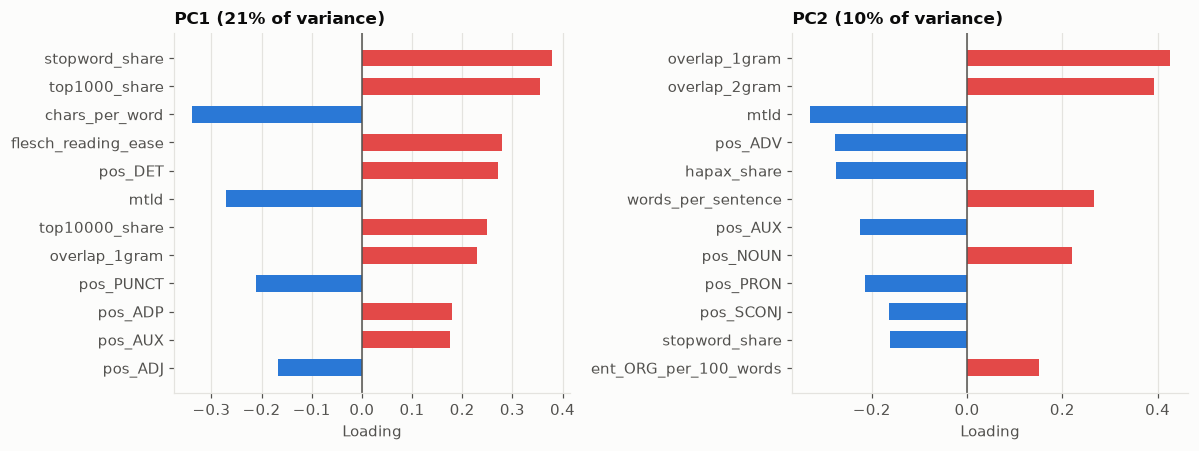

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, i in zip(axes, (0, 1)):
    loadings = pd.Series(pca.components_[i], index=used)
    top = loadings.reindex(loadings.abs().sort_values().index[-12:])
    ax.barh(top.index, top.values, color=np.where(top.values > 0, RED, BLUE), height=0.6)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set(xlabel="Loading")
    ax.set_title(f"PC{i + 1} ({explained[i]:.0f}% of variance)")
fig.tight_layout()
plt.show()

## 5. Which single features changed between BEFORE and AFTER?

For each feature: the shift of the 2024–2025 mean from the 2020–2022 mean, in 2020–2022 standard deviations,
and a Mann-Whitney test (2023 left out). With this many tests some small p-values occur by chance, so the table also shows
q-values (Benjamini-Hochberg false discovery rate). The heatmap shows every year, 2023 included, against the 2020–2022 mean.

In [8]:
pre, post = df[df.period == "before"], df[df.period == "after"]
drift = pd.DataFrame({
    "shift_sd": [(post[c].mean() - pre[c].mean()) / pre[c].std() for c in used],
    "p_value": [mannwhitneyu(pre[c], post[c]).pvalue for c in used],
}, index=used)
drift["q_value"] = false_discovery_control(drift.p_value)
drift = drift.reindex(drift.shift_sd.abs().sort_values(ascending=False).index)
print(f"{(drift.q_value < 0.05).sum()} of {len(drift)} features differ at q < 0.05")
drift.head(15).round(4)

16 of 25 features differ at q < 0.05


,shift_sd,p_value,q_value
stopword_share,-1.0470,0.0000,0.0000
top1000_share,-0.9166,0.0000,0.0000
chars_per_word,0.8322,0.0000,0.0000
flesch_reading_ease,-0.7992,0.0000,0.0000
mtld,0.6843,0.0000,0.0000
pos_DET,-0.6744,0.0000,0.0000
pos_PUNCT,0.5560,0.0000,0.0000
pos_AUX,-0.5311,0.0000,0.0000
top10000_share,-0.5022,0.0000,0.0000
overlap_1gram,-0.4741,0.0000,0.0000


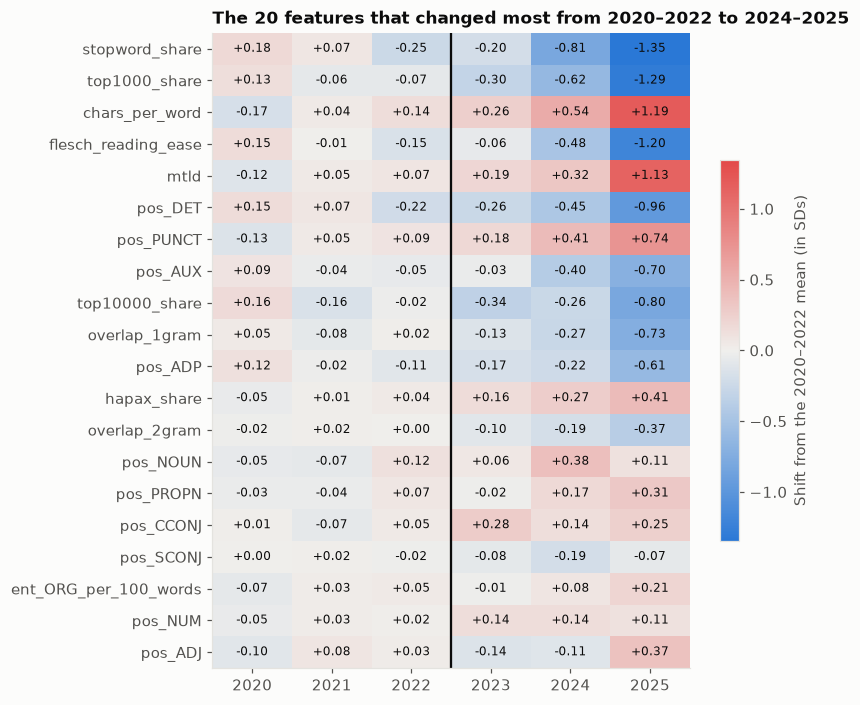

In [9]:
top = drift.index[:20]
by_year = df.groupby("year")[list(top)].mean()
shift = ((by_year - pre[top].mean()) / pre[top].std()).T
limit = np.abs(shift.values).max()

fig, ax = plt.subplots(figsize=(7, 7.5))
image = ax.imshow(shift.values, cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(years)), years)
ax.set_yticks(range(len(top)), top)
ax.grid(False)
for (r, c), value in np.ndenumerate(shift.values):
    ax.text(c, r, f"{value:+.2f}", ha="center", va="center", fontsize=8, color=TEXT)
ax.axvline(2.5, color=TEXT, linewidth=1.5)
fig.colorbar(image, ax=ax, shrink=0.6, label="Shift from the 2020–2022 mean (in SDs)")
ax.set_title("The 20 features that changed most from 2020–2022 to 2024–2025")
plt.show()

## 6. How well do the features tell the two periods apart?

A logistic regression predicts AFTER (2024–2025) vs BEFORE (2020–2022) from the features; 2023 abstracts are left out.
5-fold stratified cross-validation, AUC: 0.5 = chance, 1 = perfect.
For "PC1 + PC2 only", the scaling and the PCA are fitted inside each fold, on the training abstracts only.
This measures how much period signal the features carry. It does not say which papers are AI-written.

In [10]:
compared = df[df.period != "transition"]
y = (compared.period == "after").values
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
models = {
    "All features": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    # PCA inside the pipeline, so the test fold does not take part in fitting it.
    "PC1 + PC2 only": make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=2000)),
}
for name, model in models.items():
    auc = cross_val_score(model, compared[used], y, cv=folds, scoring="roc_auc")
    print(f"{name:<15} AUC {auc.mean():.3f} ± {auc.std():.3f}")

All features    AUC 0.783 ± 0.037


PC1 + PC2 only  AUC 0.769 ± 0.029


## 7. Is the shift only from papers about AI?

Many recent ISMIR papers study LLMs, and their abstracts might differ just because of the topic.
Here we split each year into papers that mention an AI model anywhere in the text (from `disclosure_hits_v1.csv`) and papers that don't.
If the trend also shows in papers that never mention AI, topic alone does not explain it.

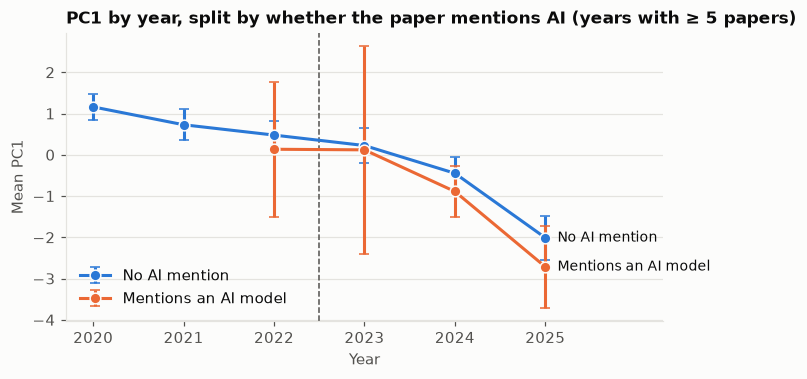

mean        size      
mentions_ai False True  False True 
year                               
2020         1.16  3.10   112     3
2021         0.73  0.84   101     3
2022         0.48  0.13   108     5
2023         0.22  0.12    94     7
2024        -0.45 -0.89    90    33
2025        -2.01 -2.71    70    29

In [11]:
hits = pd.read_csv("../data/processed/disclosure_hits_v1.csv")
ai_terms = "llm|chatgpt|gpt|generative_ai|claude|gemini"
df["mentions_ai"] = df.paper_id.isin(hits.loc[hits.terms.str.contains(ai_terms), "paper_id"])

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axvline(CHATGPT, color=MUTED, linestyle="--", linewidth=1)
for mentions, color, name in [(False, BLUE, "No AI mention"), (True, ORANGE, "Mentions an AI model")]:
    stats = df[df.mentions_ai == mentions].groupby("year").PC1.agg(["mean", "sem", "size"])
    stats = stats[stats["size"] >= 5]  # too few papers for a stable mean
    ax.errorbar(stats.index, stats["mean"], yerr=1.96 * stats["sem"], color=color, linewidth=2, marker="o",
                markersize=7, markeredgecolor=SURFACE, capsize=3, label=name)
    ax.annotate(name, (stats.index[-1], stats["mean"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=TEXT)
ax.set(xlabel="Year", ylabel="Mean PC1", xticks=sorted(df.year.unique()), xlim=(2019.7, 2026.3))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower left")
ax.set_title("PC1 by year, split by whether the paper mentions AI (years with ≥ 5 papers)")
plt.show()
df.groupby(["year", "mentions_ai"]).PC1.agg(["mean", "size"]).round(2).unstack()

## Findings (features_v1: 25 style features, `n_words` left out)

BEFORE = 2020–2022, AFTER = 2024–2025. 2023 is a transition year: it is in the PCA and the plots, not in the comparisons.

1. **No separate "AI" cluster.** PC1 and PC2 explain 30% of the variance, and every year overlaps with every other year.
   This is expected: LLM help is partial and mixed into human text, so it moves papers along a direction rather than into a new group.
2. **There is a clear time trend on PC1.** Lower PC1 means fewer stop words and very common words, fewer determiners, longer words,
   more varied vocabulary (MTLD), more punctuation and a lower Flesch reading score. 16 of 25 features differ between BEFORE and AFTER
   at q < 0.05. The largest shifts (in 2020–2022 SDs) are `stopword_share` −1.05, `top1000_share` −0.92, `chars_per_word` +0.83,
   `flesch_reading_ease` −0.80 and `mtld` +0.68.
3. **Length does not explain it.** The median abstract length stays between 167 and 181 words in every year, and length is not a feature.
4. **The trend started before ChatGPT; only 2025 clearly leaves it.** Mean PC1 fell from 1.21 (2020) to 0.46 (2022), 0.22 (2023),
   −0.57 (2024) and −2.22 (2025). Against the 2020–2022 linear trend, the excess is +0.16 in 2023 (95% CI −0.50 to 0.78),
   −0.24 in 2024 (−1.05 to 0.51) and −1.52 in 2025 (−2.60 to −0.45). The placebo (2022 from the 2020–2021 trend) gives +0.21
   (−0.66 to 1.08), so the method finds no excess where none is expected. 2023 and 2024 are within the extended trend; 2025 is below it.
   A plain BEFORE vs AFTER comparison therefore overstates the effect.
5. **Papers about AI do not explain it.** Papers that never mention an AI model follow the same trend (2025: −2.01).
6. **The period signal is moderate.** Predicting AFTER vs BEFORE from the features gives AUC 0.78 ± 0.04 (all features)
   and 0.77 ± 0.03 (PC1 + PC2 only). Part of this signal is the pre-existing trend, not an effect of ChatGPT.

Next step: the synthetic abstracts (`analysis/generate.py`) give real LLM labels. If human → LLM moves abstracts in the same
PC1 direction as 2022 → 2025, that supports LLM influence. If it points elsewhere, the drift has another cause.
To compare them, fit the scaler and the PCA on the human abstracts only and project the synthetic ones onto it.